# Visual data analysis in Python

In [1]:
# Matplotlib forms basis for visualization in Python
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# We will use the Seaborn library
import seaborn as sns

sns.set()

# Graphics in SVG format are more sharp and legible
%config InlineBackend.figure_format = 'svg'

In [2]:
df = pd.read_csv("./telecom_churn.csv")
df.head()

,State,Account length,Area code,International plan,Voice mail plan,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,Total eve charge,Total night minutes,Total night calls,Total night charge,Total intl minutes,Total intl calls,Total intl charge,Customer service calls,Churn
0,KS,128,415,No,Yes,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,107,415,No,Yes,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,137,415,No,No,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,OH,84,408,Yes,No,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,OK,75,415,Yes,No,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False


## Univariate visualization

#### Types of features:
1. Quantitative
2. Qualitative
   1. Binary
   2. Non-binary
   3. Ordinal

### Quantitative features 
Quantitative features take on ordered numerical values.<br />
Types:
1. Descrete
2. Continuous

#### Histograms and density plots

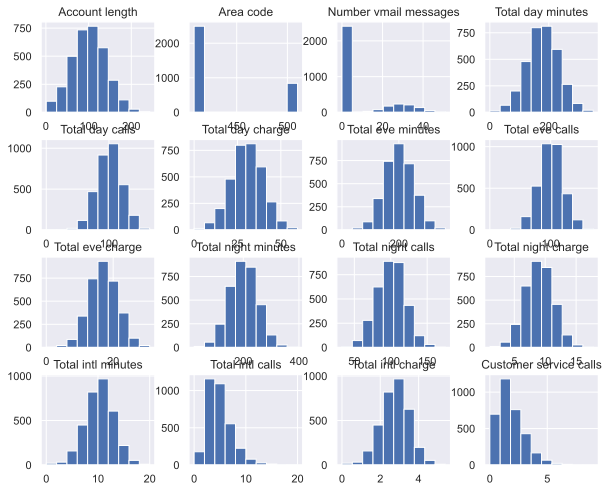

In [3]:
df.hist(figsize=(10, 8)); # it's so long

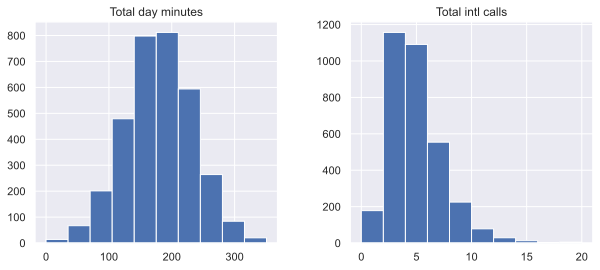

In [4]:
features = ["Total day minutes", "Total intl calls"]
df[features].hist(figsize=(10, 4));

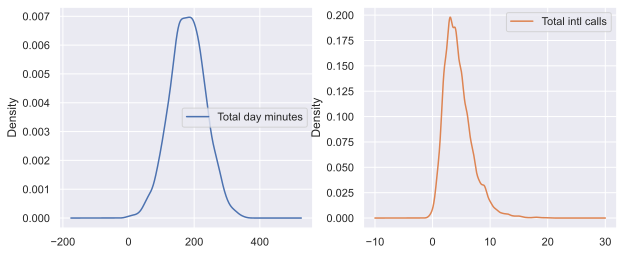

In [5]:
df[features].plot(
    kind="density", # type of a plot
    subplots=True, # two separate plots or one common plot
    layout=(1, 2), # two subplots in one line. otherwise, vertically
    sharex=False, # Otherwise, both subplots would have identical X-axe
    figsize=(10, 4)
);

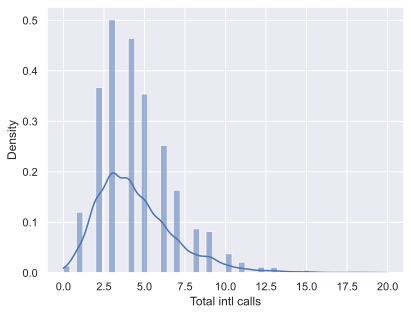

In [6]:
sns.histplot(df["Total intl calls"], kde=True, stat="density"); # plot with histogramma

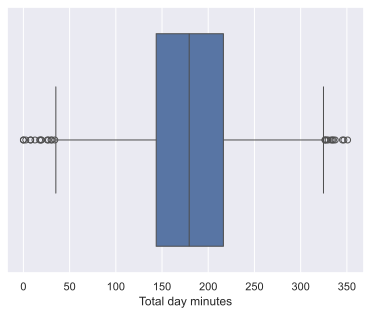

In [7]:
sns.boxplot(x = "Total day minutes", data=df);

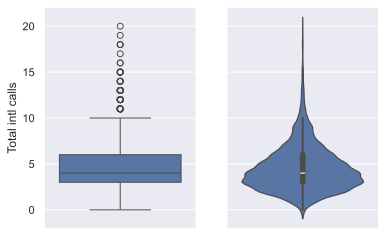

In [8]:
_, axes = plt.subplots(1, 2, sharey=True, figsize=(6, 4))
sns.boxplot(data=df["Total intl calls"], ax=axes[0])
sns.violinplot(data=df["Total intl calls"], ax=axes[1]);

**Smoothed distribution (сглаженное распределение)** — это математический или графический способ показать общую форму и тенденцию непрерывных данных, убрав из них случайный «шум», мелкие неровности и резкие скачки.
Вместо того чтобы строить угловатую гистограмму, данные превращают в плавную, непрерывную линию. 

**Kernel Density Estimate (KDE, Ядерная оценка плотности)** — это статистический метод, который превращает набор отдельных точек данных в плавную, непрерывную линию распределения.
Это как раз тот алгоритм, который создает smoothed distribution, о котором мы говорили ранее. Вместо того чтобы разбивать данные на жесткие прямоугольные столбцы (как в гистограмме), KDE сглаживает каждую отдельную точку и объединяет их в единую кривую.

In [9]:
df.describe()

,Account length,Area code,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,Total eve charge,Total night minutes,Total night calls,Total night charge,Total intl minutes,Total intl calls,Total intl charge,Customer service calls
count,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000
mean,101.064806,437.182418,8.099010,179.775098,100.435644,30.562307,200.980348,100.114311,17.083540,200.872037,100.107711,9.039325,10.237294,4.479448,2.764581,1.562856
std,39.822106,42.371290,13.688365,54.467389,20.069084,9.259435,50.713844,19.922625,4.310668,50.573847,19.568609,2.275873,2.791840,2.461214,0.753773,1.315491
min,1.000000,408.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,23.200000,33.000000,1.040000,0.000000,0.000000,0.000000,0.000000
25%,74.000000,408.000000,0.000000,143.700000,87.000000,24.430000,166.600000,87.000000,14.160000,167.000000,87.000000,7.520000,8.500000,3.000000,2.300000,1.000000
50%,101.000000,415.000000,0.000000,179.400000,101.000000,30.500000,201.400000,100.000000,17.120000,201.200000,100.000000,9.050000,10.300000,4.000000,2.780000,1.000000
75%,127.000000,510.000000,20.000000,216.400000,114.000000,36.790000,235.300000,114.000000,20.000000,235.300000,113.000000,10.590000,12.100000,6.000000,3.270000,2.000000
max,243.000000,510.000000,51.000000,350.800000,165.000000,59.640000,363.700000,170.000000,30.910000,395.000000,175.000000,17.770000,20.000000,20.000000,5.400000,9.000000


### Categorical and binary features

*Categorical features* take on a fixed number of values. Each of these values assigns an observation to a corresponding group, known as a category, which reflects some qualitative property of this example. *Binary* variables are an important special case of categorical variables when the number of possible values is exactly 2. If the values of a categorical variable are ordered, it is called *ordinal*.

In [10]:
df["Churn"].value_counts()

Churn
False    2850
True      483
Name: count, dtype: int64

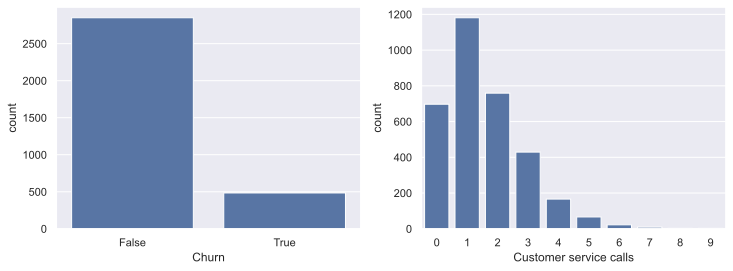

In [12]:
_, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 4))

sns.countplot(x="Churn", data=df, ax=axes[0])
sns.countplot(x="Customer service calls", data=df, ax=axes[1]);

## Multivariate visualization

Multivariate plots allow us to see relationships between two and more different variables, all in one figure. Depends on the types of the variables

### Quantitative vs. Quantitative

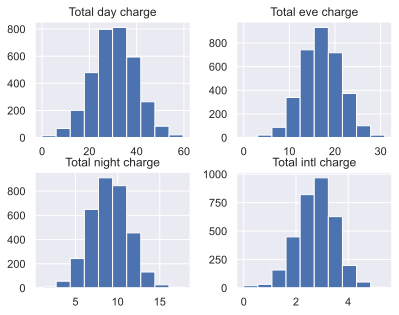

In [15]:
features = [f for f in df.columns if "charge" in f]
df[features].hist();

#### Correlation matrix

Let’s look at the correlations among the numerical variables in our dataset.

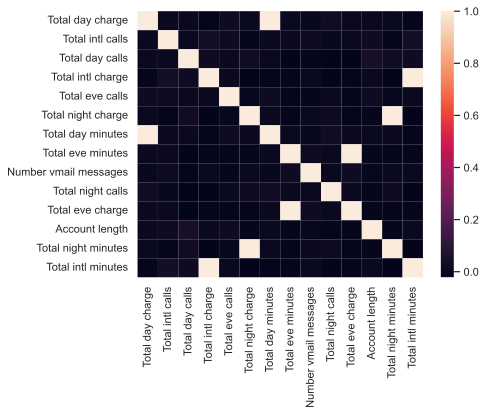

In [32]:
# Drop non-numerical variables
non_numerical = [
    "State",
    "International plan",
    "Voice mail plan",
    "Area code",
    "Churn",
    "Customer service calls",
]

numerical = list(
    set(df.columns) - set(non_numerical)
)

# Calculate and plot
corr_matrix = df[numerical].corr() # or corr_matrix = df.drop(non_numerical, axis=1).corr()
sns.heatmap(corr_matrix);

#### Scatter plot

The scatter plot displays values of two numerical variables as Cartesian coordinates in 2D space. Scatter plots in 3D are also possible

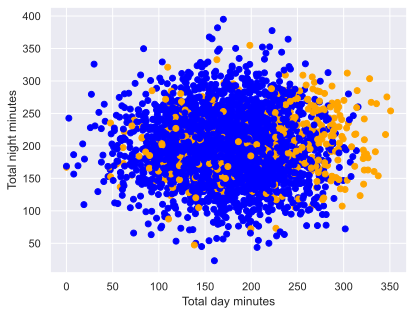

In [24]:
colours = df["Churn"].map({True: "orange", False: "blue"});
plt.scatter(df["Total day minutes"], df["Total night minutes"], color=colours);
plt.xlabel("Total day minutes");
plt.ylabel("Total night minutes");

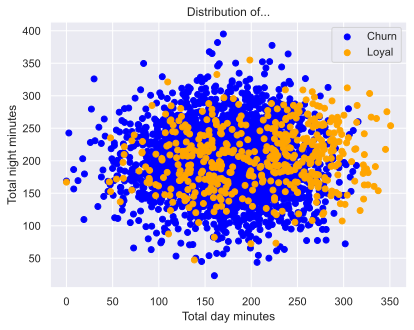

In [27]:
nonloyal = df[df["Churn"]]
loyal = df[~df["Churn"]]
plt.scatter(loyal["Total day minutes"], loyal["Total night minutes"], color="blue", label="Churn");
plt.scatter(nonloyal["Total day minutes"], nonloyal["Total night minutes"], color="orange", label="Loyal");
plt.xlabel("Total day minutes");
plt.ylabel("Total night minutes");
plt.title("Distribution of...")
plt.legend();

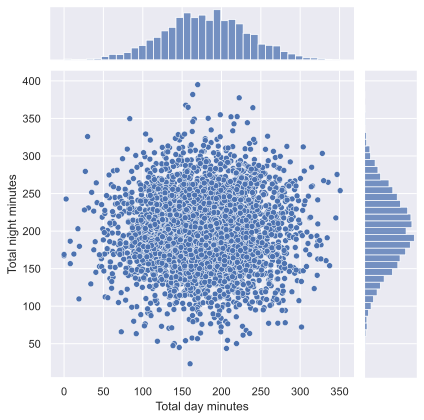

In [19]:
sns.jointplot(x="Total day minutes", y="Total night minutes", data=df, kind="scatter");

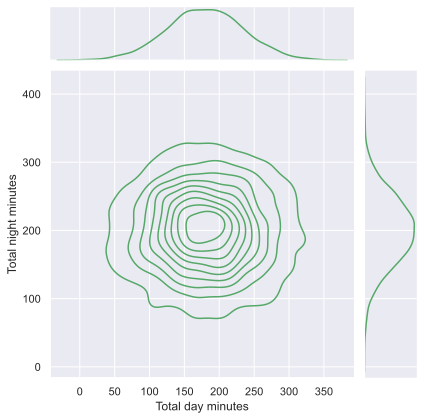

In [33]:
sns.jointplot(
    x="Total day minutes", y="Total night minutes", data=df, kind="kde", color="g"
);

#### Scatterplot matrix

In some cases, we may want to plot a scatterplot matrix such as the one shown below. Its diagonal contains the distributions of the corresponding variables, and the scatter plots for each pair of variables fill the rest of the matrix.

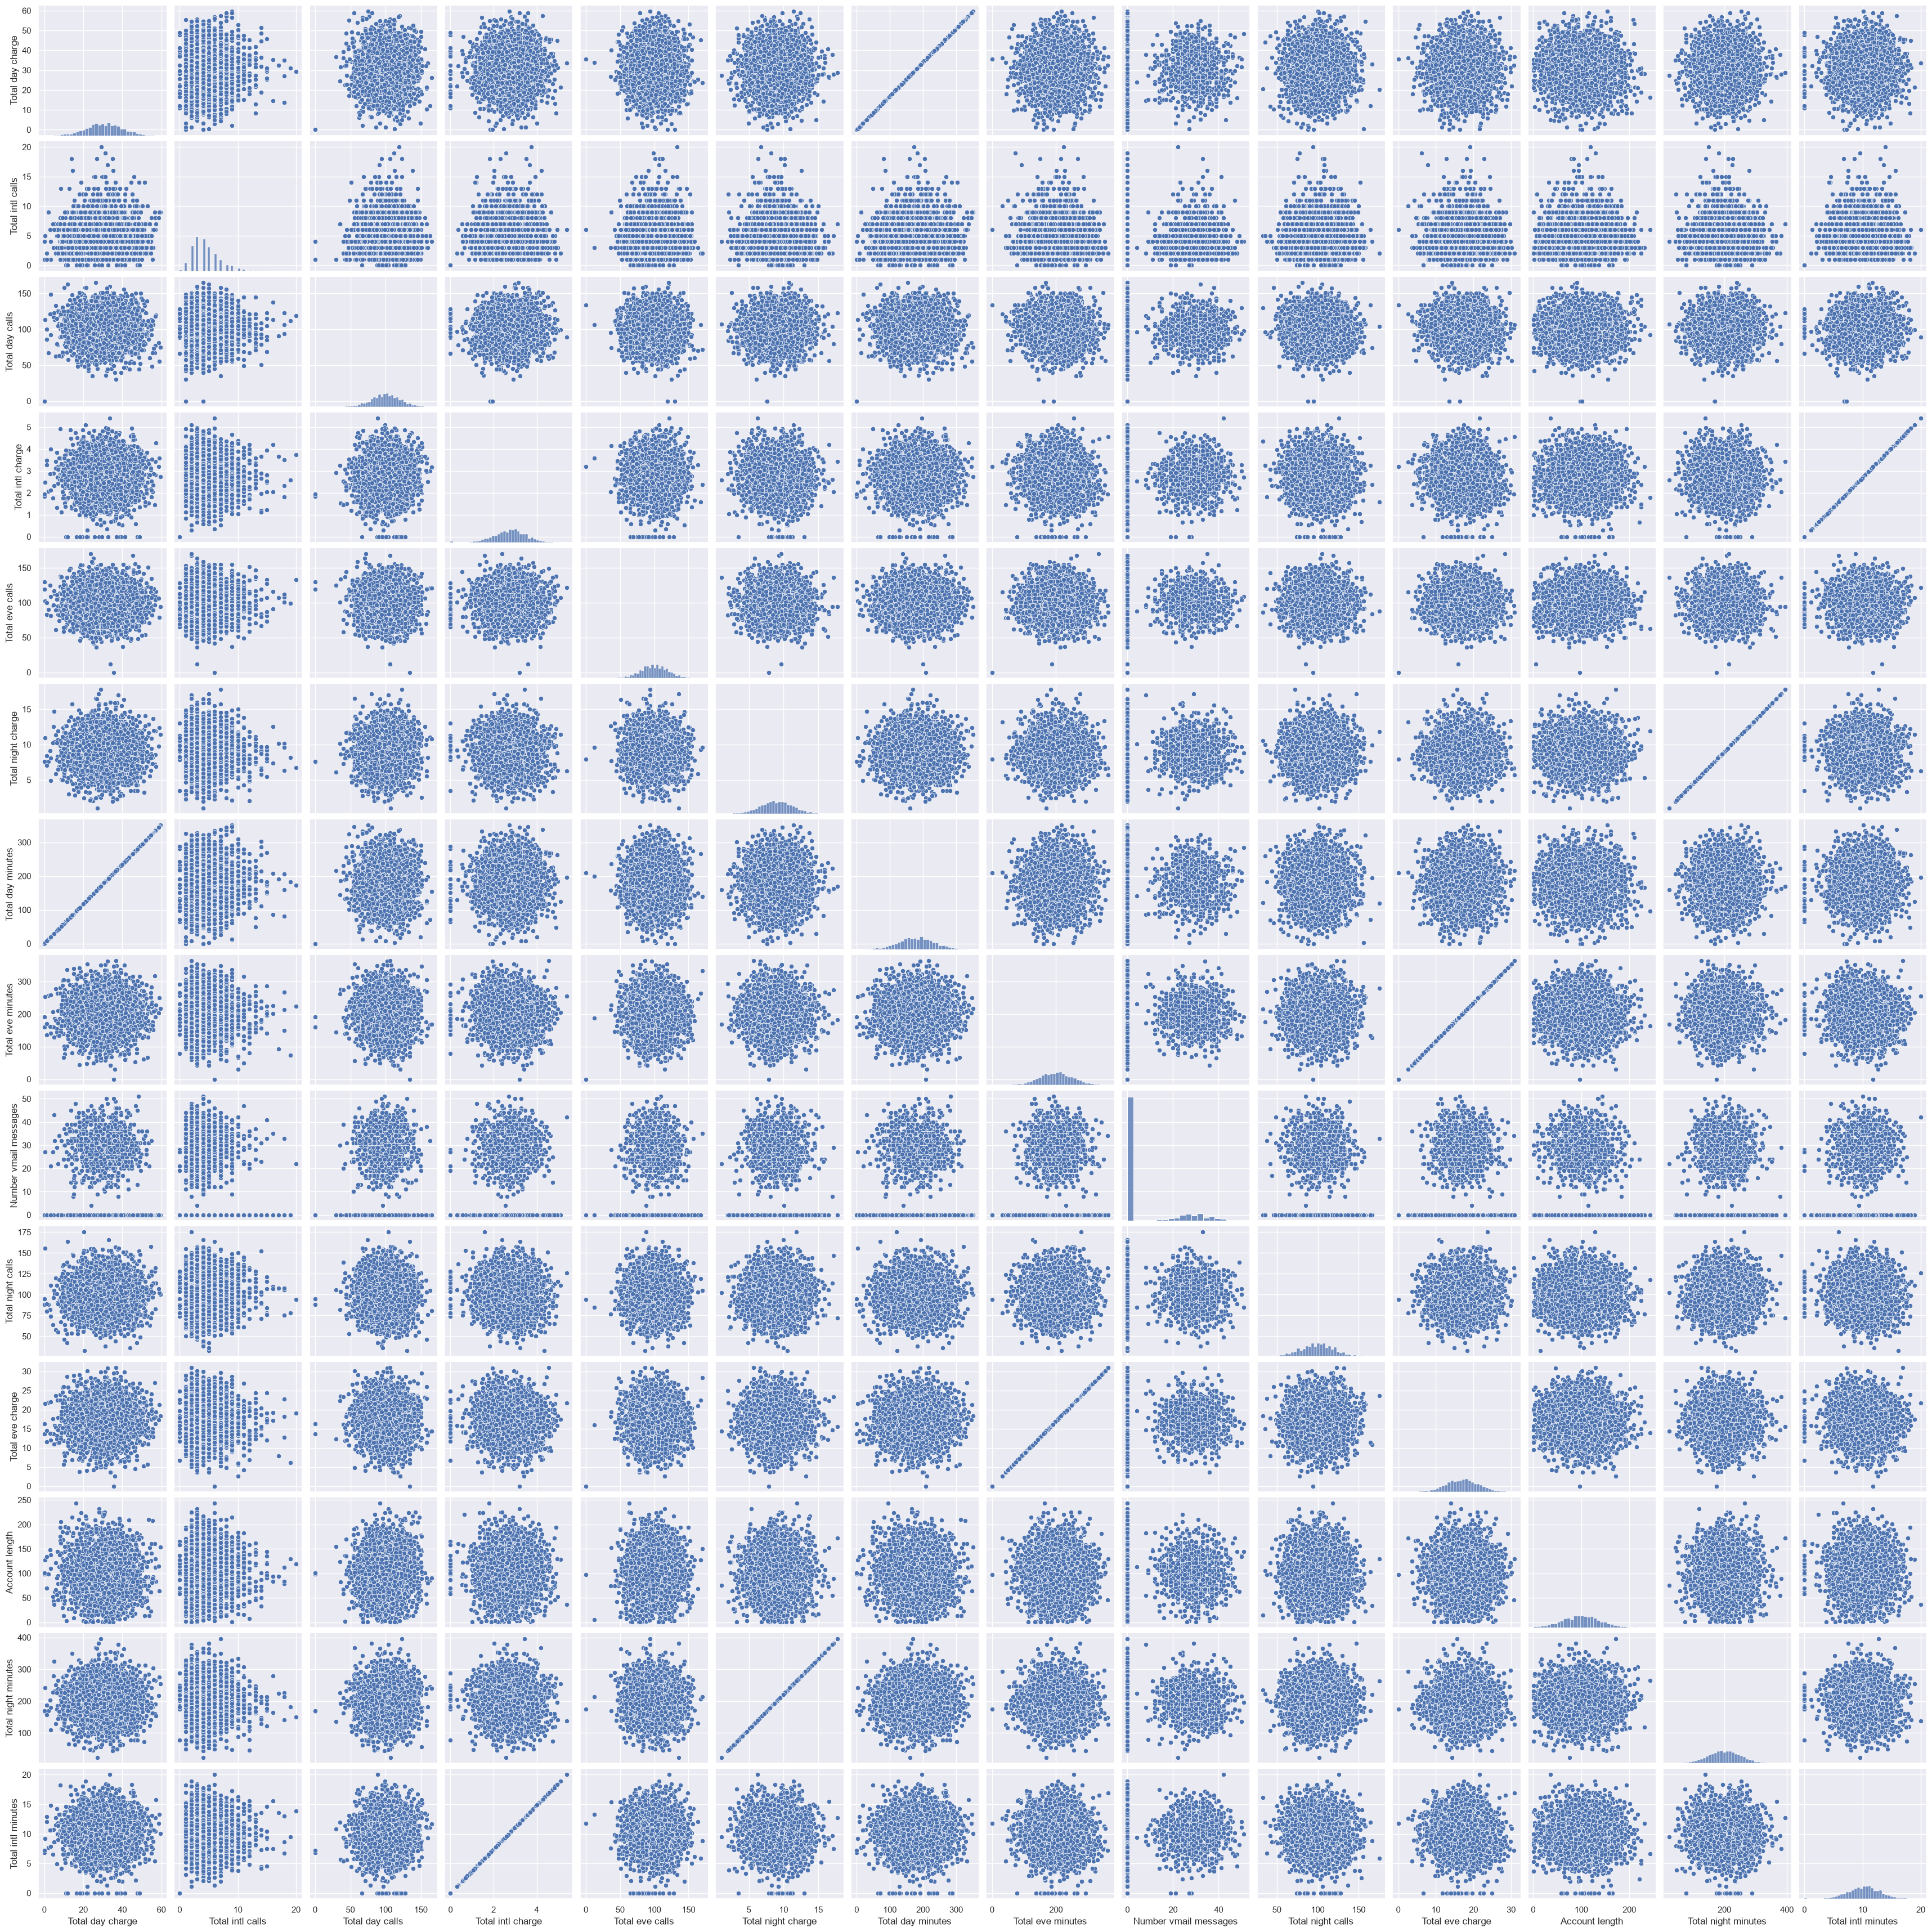

In [34]:
# `pairplot()` may become very slow with the SVG format
%config InlineBackend.figure_format = 'png'
sns.pairplot(df[numerical]);

### Quantitative vs. Categorical

Previously, you learned about scatter plots. Additionally, their points can be color- or size-coded so that the values of a third categorical variable are also presented in the same figure. We can achieve this with the scatter() function seen above, but let’s try a new function called lmplot() and use the parameter hue to indicate our categorical feature of interest:

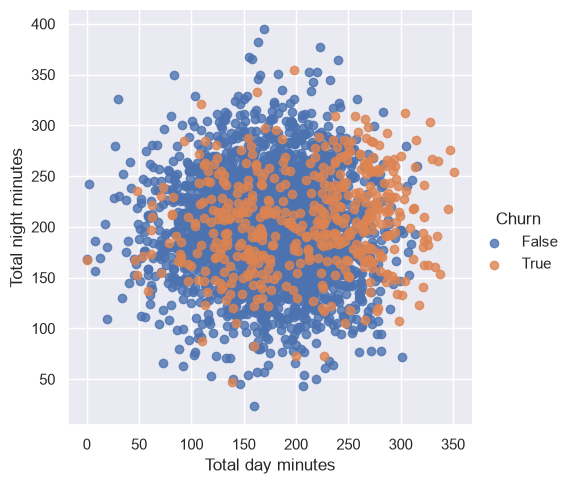

In [36]:
sns.lmplot(
    x="Total day minutes", y="Total night minutes", data=df, hue="Churn", fit_reg=False
);

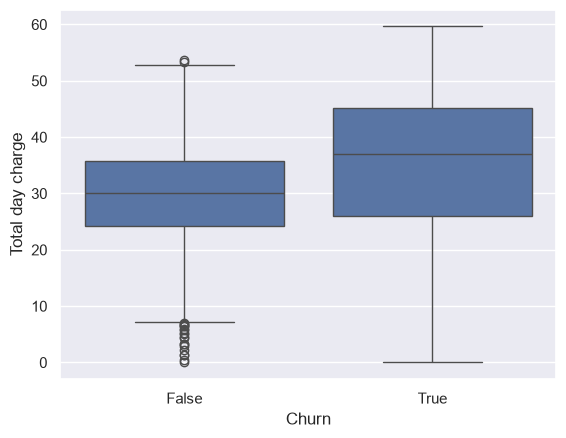

In [38]:
sns.boxplot(x="Churn", y=numerical[0], data=df);

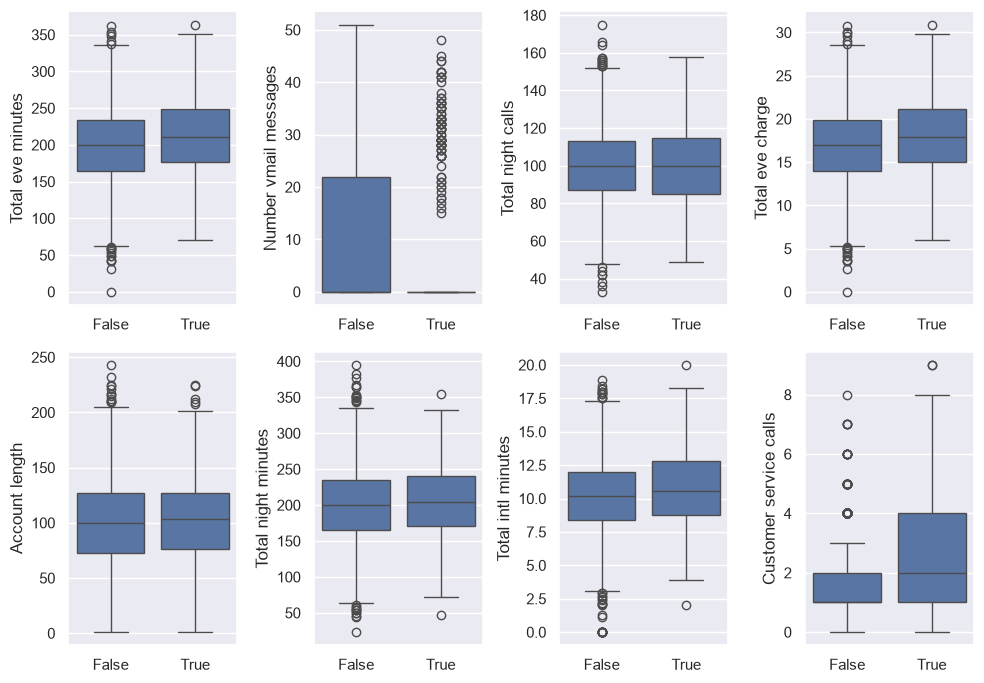

In [48]:
numerical = [
 'Total eve minutes',
 'Number vmail messages',
 'Total night calls',
 'Total eve charge',
 'Account length',
 'Total night minutes',
 'Total intl minutes',
 'Customer service calls'
]

fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(10, 7))
for idx, feat in enumerate(numerical):
    ax = axes[int(idx / 4), idx % 4]
    sns.boxplot(x="Churn", y=feat, data=df, ax=ax)
    ax.set_xlabel("")
    ax.set_ylabel(feat)
fig.tight_layout();

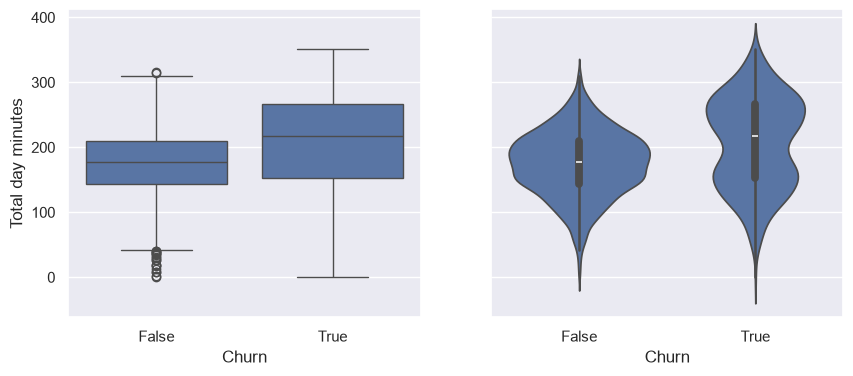

In [49]:
_, axes = plt.subplots(1, 2, sharey=True, figsize=(10, 4))

sns.boxplot(x="Churn", y="Total day minutes", data=df, ax=axes[0])
sns.violinplot(x="Churn", y="Total day minutes", data=df, ax=axes[1]);

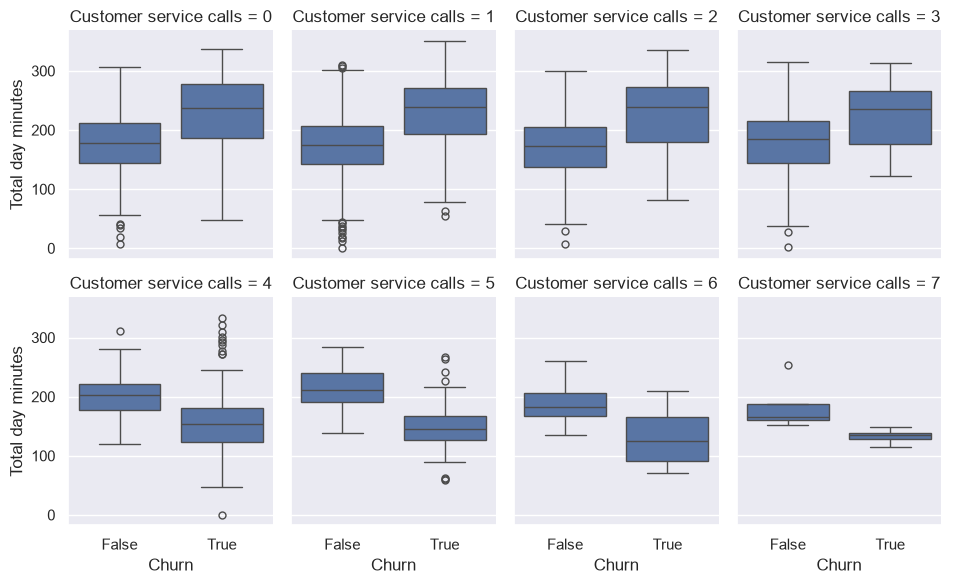

In [50]:
sns.catplot(
    x="Churn",
    y="Total day minutes",
    col="Customer service calls",
    data=df[df["Customer service calls"] < 8],
    kind="box",
    col_wrap=4,
    height=3,
    aspect=0.8,
);

### Categorical vs. Categorical

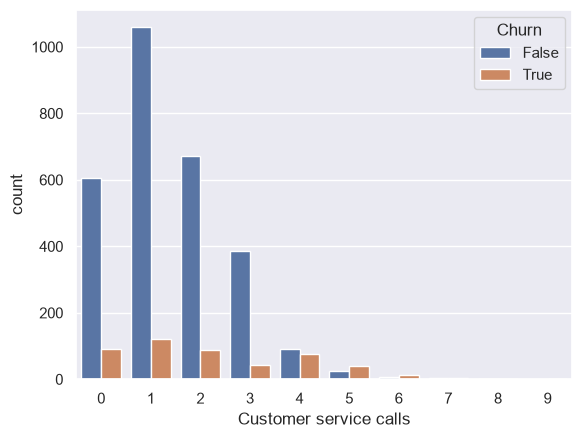

In [53]:
sns.countplot(x="Customer service calls", hue="Churn", data=df);

#### Contingency table

In addition to using graphical means for categorical analysis, there is a traditional tool from statistics: a contingency table, also called a cross tabulation. It shows a multivariate frequency distribution of categorical variables in tabular form. In particular, it allows us to see the distribution of one variable conditional on the other by looking along a column or row.

Let’s try to see how Churn is related to the categorical variable State by creating a cross tabulation:

In [54]:
pd.crosstab(df["State"], df["Churn"]).T

State,AK,AL,AR,AZ,CA,CO,CT,DC,DE,FL,...,SD,TN,TX,UT,VA,VT,WA,WI,WV,WY
Churn,,,,,,,,,,,,,,,,,,,,,
False,49,72,44,60,25,57,62,49,52,55,...,52,48,54,62,72,65,52,71,96,68
True,3,8,11,4,9,9,12,5,9,8,...,8,5,18,10,5,8,14,7,10,9


#### Dimensionality reduction

**Most real-world datasets have many features, sometimes, many thousands of them**. Each of them can be considered as a dimension in the space of data points. Consequently, more often than not, we deal with high-dimensional datasets, where **entire visualization is quite hard**.

To look at a dataset as a whole, **we need to decrease the number of dimensions used in visualization without losing much information about the data**. This task is called dimensionality reduction and is an example of an unsupervised learning problem because we need to derive new, low-dimensional features from the data itself, without any supervised input.

One of the well-known dimensionality reduction methods is **Principal Component Analysis (PCA)**, which we will study later in this course. Its limitation is that it is a linear algorithm that implies certain restrictions on the data.

There are also many non-linear methods, collectively called **Manifold Learning**. One of the best-known of them is **t-SNE**.